# HOMEWORK 3


In [19]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [20]:
df=pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [21]:
#loading dataframe
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### Data preparation

In [22]:
# Check if the missing values are presented in the features.
df.isna().any()

lead_source                  True
industry                     True
employment_status            True
location                     True
annual_income                True
number_of_courses_viewed    False
interaction_count           False
lead_score                   True
converted                   False
dtype: bool

In [23]:
#If there are missing values:
  #For categorical features, replace them with 'NA'
categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']
df[categorical_cols] = df[categorical_cols].fillna('NA')

  #For numerical features, replace with with 0.0
numerical_cols = ['annual_income', 'lead_score']
df[numerical_cols] = df[numerical_cols].fillna(0.0)

In [24]:
#Question 1: What is the most frequent observation (mode) for the column industry?
df['industry'].mode()[0]

'technology'

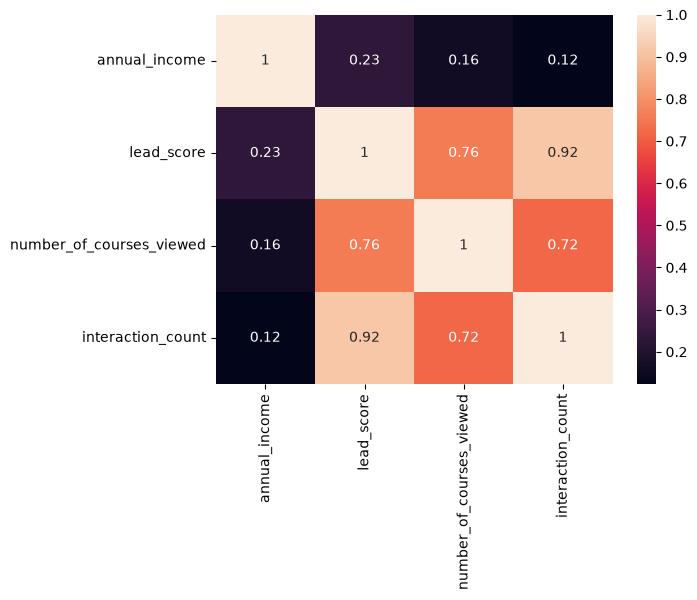

In [25]:
#Question 2
#Create the correlation matrix for the numerical features of your dataset. In a correlation matrix, you compute the correlation coefficient between every pair of features.
numf_dataset = ['annual_income', 'lead_score', 'number_of_courses_viewed', 'interaction_count']
sns.heatmap(df[numf_dataset].corr(), annot=True)
plt.show()
# What are the two features that have the biggest correlation?
#the two features that have the biggest correlation are interaction_count and lead_score


### Split the data


In [26]:
#Split the data with these exact calls:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [27]:
#Make sure that the target value converted is not in your dataframe.
    # Extract target values
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

    # Remove the target from features
df_train = df_train.drop(columns=['converted'])
df_val = df_val.drop(columns=['converted'])
df_test = df_test.drop(columns=['converted'])

In [28]:
#Question 3
    #Calculate the mutual information score between converted and other categorical variables in the dataset. Use the training set only.
categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']
mi_scores = {}

for col in categorical_cols:
    score = mutual_info_score(df_train[col], y_train)
    #Round the scores to 2 decimals using round(score, 2).
    mi_scores[col] = round(score, 2)
    
print(mi_scores)
# the biggest mutual information score is lead_source 


{'lead_source': 0.03, 'industry': 0.0, 'employment_status': 0.02, 'location': 0.0}


In [29]:
#Question 4
 #4.1.Now let's train a logistic regression.
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

   #4.2Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
     #4.3.Fit the model on the training dataset.
#To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:
#model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

#4.3.Calculate the accuracy on the validation dataset and round it to 2 decimal digits.
    # Make predictions
y_pred = model.predict(X_val)
# Calculate accuracy
accuracy = accuracy_score(y_val, y_pred)

print("Accuracy:", round(accuracy, 2))


Accuracy: 0.65


In [30]:
# Question 5
 #5.1. Train a model using the same features and parameters as in Q4 (without rounding).
def train_model(df_train, df_val):
    dv = DictVectorizer(sparse=False)

    X_train = dv.fit_transform(df_train.to_dict(orient='records'))
    X_val = dv.transform(df_val.to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    return accuracy_score(y_val, y_pred)
# Original accuracy (without rounding)
original_accuracy = train_model(df_train, df_val)
#5.2. For each feature, calculate the difference between the original accuracy and the accuracy without the feature.
features = ['lead_source','number_of_courses_viewed','interaction_count']

differences = {}

for feature in features:
    train = df_train.drop(columns=[feature])
    val = df_val.drop(columns=[feature])
    accuracy = train_model(train, val)
    diff = original_accuracy - accuracy
    differences[feature] = diff
    print(feature)
    print("Accuracy:", accuracy)
    print("Difference:", diff)
    print()

#5.3. Let's find the least useful feature using the feature elimination technique.
least_useful = min(
    differences,
    key=lambda f: abs(differences[f])
)

print("Original accuracy:", original_accuracy)
print("Answer Q5:", least_useful)

lead_source
Accuracy: 0.642
Difference: 0.0030000000000000027

number_of_courses_viewed
Accuracy: 0.643
Difference: 0.0020000000000000018

interaction_count
Accuracy: 0.601
Difference: 0.04400000000000004

Original accuracy: 0.645
Answer Q5: number_of_courses_viewed


In [18]:
# Question 6
#Train models using all the features as in Q4.
# One-Hot Encoding
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))

# Let's try the following values of the parameter C: [0.000001, 0.00001, 0.0001, 0.001].
C_values = [0.000001, 0.00001, 0.0001, 0.001]
scores = {}
#Now let's train a regularized logistic regression.
for c in C_values:
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000,random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    # Calculate the accuracy on the validation dataset and round it to 3 decimal digits.
    accuracy = accuracy_score(y_val, y_pred)
    scores[c] = round(accuracy, 3)
    print(f"C = {c}, Accuracy = {scores[c]}")
best_c = max(scores, key=scores.get)

print("Best C:", best_c)
print("Best Accuracy:", scores[best_c])

C = 1e-06, Accuracy = 0.598
C = 1e-05, Accuracy = 0.598
C = 0.0001, Accuracy = 0.613
C = 0.001, Accuracy = 0.645
Best C: 0.001
Best Accuracy: 0.645
